In [1]:
import sys
import pandas as pd, sklearn, xgboost

print(sys.executable)
print(pd.__version__, sklearn.__version__, xgboost.__version__)

d:\midterm-lapse-risk\.venv\Scripts\python.exe
3.1.1 1.9.1 3.4.1


In [1]:
from pathlib import Path
import pandas as pd

raw = Path("../data/raw")
for f in sorted(raw.glob("*.csv")):
    size_mb = f.stat().st_size / 1e6
    df = pd.read_csv(f, nrows=3)
    print(f"{f.name}  ({size_mb:.1f} MB)")
    print(list(df.columns))
    print()

campaign_desc.csv  (0.0 MB)
['DESCRIPTION', 'CAMPAIGN', 'START_DAY', 'END_DAY']

campaign_table.csv  (0.1 MB)
['DESCRIPTION', 'household_key', 'CAMPAIGN']

causal_data.csv  (695.9 MB)
['PRODUCT_ID', 'STORE_ID', 'WEEK_NO', 'display', 'mailer']

coupon.csv  (2.8 MB)
['COUPON_UPC', 'PRODUCT_ID', 'CAMPAIGN']

coupon_redempt.csv  (0.1 MB)
['household_key', 'DAY', 'COUPON_UPC', 'CAMPAIGN']

hh_demographic.csv  (0.0 MB)
['classification_1', 'classification_2', 'classification_3', 'HOMEOWNER_DESC', 'classification_5', 'classification_4', 'KID_CATEGORY_DESC', 'household_key']

product.csv  (6.4 MB)
['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']

transaction_data.csv  (141.7 MB)
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC']



In [2]:
from pathlib import Path
import pandas as pd

raw = Path("../data/raw")
for f in sorted(raw.glob("*.csv")):
    size_mb = f.stat().st_size / 1e6
    df = pd.read_csv(f, nrows=3)
    print(f"{f.name}  ({size_mb:.1f} MB)")
    print(list(df.columns))
    print()

campaign_desc.csv  (0.0 MB)
['DESCRIPTION', 'CAMPAIGN', 'START_DAY', 'END_DAY']

campaign_table.csv  (0.1 MB)
['DESCRIPTION', 'household_key', 'CAMPAIGN']

causal_data.csv  (695.9 MB)
['PRODUCT_ID', 'STORE_ID', 'WEEK_NO', 'display', 'mailer']

coupon.csv  (2.8 MB)
['COUPON_UPC', 'PRODUCT_ID', 'CAMPAIGN']

coupon_redempt.csv  (0.1 MB)
['household_key', 'DAY', 'COUPON_UPC', 'CAMPAIGN']

hh_demographic.csv  (0.0 MB)
['classification_1', 'classification_2', 'classification_3', 'HOMEOWNER_DESC', 'classification_5', 'classification_4', 'KID_CATEGORY_DESC', 'household_key']

product.csv  (6.4 MB)
['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']

transaction_data.csv  (141.7 MB)
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC']



In [3]:
tx = pd.read_csv(raw / "transaction_data.csv")

print("shape:", tx.shape)
tx.info()
print()
print("households:", tx["household_key"].nunique())
print("baskets:", tx["BASKET_ID"].nunique())
print("DAY range:", tx["DAY"].min(), "to", tx["DAY"].max())
print("WEEK_NO range:", tx["WEEK_NO"].min(), "to", tx["WEEK_NO"].max())
print("rows where WEEK_NO == DAY//7 + 1:", (tx["DAY"] // 7 + 1 == tx["WEEK_NO"]).mean())
print()
print(tx.isna().sum())
print()
print(tx[["QUANTITY", "SALES_VALUE", "RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC"]].describe())

shape: (2595732, 12)
<class 'pandas.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB

households: 2500
baskets: 276484
DAY range: 1 to 711
WEEK_NO range: 1 to 102
rows where WEEK_NO == DAY//7 + 1: 0.860397760631683

household_key        0
BASKET_ID            0
DAY                  0
PRODUCT_ID           0
QUANTITY             0
SALES_VALUE          0
STORE_ID             0
RETAIL_DISC          0
TRANS_TIME           0
WEEK_NO              0
COUPON_DISC     

In [4]:
for name in ["campaign_desc", "campaign_table", "coupon_redempt", "hh_demographic"]:
    d = pd.read_csv(raw / f"{name}.csv")
    print(name, d.shape)

print(pd.read_csv(raw / "campaign_desc.csv"))

campaign_desc (30, 4)
campaign_table (7208, 3)
coupon_redempt (2318, 4)
hh_demographic (801, 8)
   DESCRIPTION  CAMPAIGN  START_DAY  END_DAY
0        TypeB        24        659      719
1        TypeC        15        547      708
2        TypeB        25        659      691
3        TypeC        20        615      685
4        TypeB        23        646      684
5        TypeB        21        624      656
6        TypeB        22        624      656
7        TypeA        18        587      642
8        TypeB        19        603      635
9        TypeB        17        575      607
10       TypeC        14        531      596
11       TypeB        16        561      593
12       TypeA        13        504      551
13       TypeB        11        477      523
14       TypeB        12        477      509
15       TypeB        10        463      495
16       TypeB         9        435      467
17       TypeA         8        412      460
18       TypeB         7        398      432
19  

In [5]:
print("total missing values:", tx.isna().sum().sum())
print("WEEK_NO matches day:", ((tx["DAY"] - 1) // 7 + 1 == tx["WEEK_NO"]).mean())
print("rows with SALES_VALUE <= 0:", (tx["SALES_VALUE"] <= 0).sum())
print("rows with QUANTITY <= 0:", (tx["QUANTITY"] <= 0).sum())
print(tx[["QUANTITY", "SALES_VALUE"]].describe().round(2))

total missing values: 0
WEEK_NO matches day: 0.7324646766307154
rows with SALES_VALUE <= 0: 18850
rows with QUANTITY <= 0: 14466
         QUANTITY  SALES_VALUE
count  2595732.00   2595732.00
mean       100.43         3.10
std       1153.44         4.18
min          0.00         0.00
25%          1.00         1.29
50%          1.00         2.00
75%          1.00         3.49
max      89638.00       840.00


In [6]:
weekly = (
    tx.groupby(["household_key", "WEEK_NO"])
      .agg(spend=("SALES_VALUE", "sum"), baskets=("BASKET_ID", "nunique"))
      .reset_index()
)
print("household-weeks:", weekly.shape)

hh = weekly.groupby("household_key")["WEEK_NO"].agg(
    first_week="min", last_week="max", active_weeks="nunique"
)
print(hh.describe().round(1))

def lapse_rate(cutoff_week, horizon=4):
    seen = set(weekly.loc[weekly["WEEK_NO"] <= cutoff_week, "household_key"])
    window = weekly[(weekly["WEEK_NO"] > cutoff_week) &
                    (weekly["WEEK_NO"] <= cutoff_week + horizon)]
    returned = set(window["household_key"])
    return len(seen), round(1 - len(seen & returned) / len(seen), 3)

for w in [10, 20, 40, 60, 80, 98]:
    print("cutoff week", w, "-> (eligible households, lapse rate):", lapse_rate(w))

household-weeks: (123976, 4)
       first_week  last_week  active_weeks
count      2500.0     2500.0        2500.0
mean         10.1       98.6          49.6
std           5.6        9.0          25.5
min           1.0        8.0           1.0
25%           6.0       99.0          28.0
50%          11.0      101.0          50.0
75%          14.0      102.0          71.0
max          97.0      102.0         102.0
cutoff week 10 -> (eligible households, lapse rate): (1237, 0.18)
cutoff week 20 -> (eligible households, lapse rate): (2493, 0.204)
cutoff week 40 -> (eligible households, lapse rate): (2497, 0.207)
cutoff week 60 -> (eligible households, lapse rate): (2497, 0.195)
cutoff week 80 -> (eligible households, lapse rate): (2498, 0.189)
cutoff week 98 -> (eligible households, lapse rate): (2500, 0.204)


In [7]:
wk = tx.groupby("WEEK_NO")["DAY"].agg(["min", "max"])
print(wk.head(4)); print(wk.tail(3))

print("household-weeks with spend <= 0:", (weekly["spend"] <= 0).sum())
print("share of rows with QUANTITY > 100:", (tx["QUANTITY"] > 100).mean().round(4))
print(tx.loc[tx["QUANTITY"] > 1000, ["QUANTITY", "SALES_VALUE"]].head())

         min  max
WEEK_NO          
1          1    5
2          6   12
3         13   19
4         20   26
         min  max
WEEK_NO          
100      692  698
101      699  705
102      706  711
household-weeks with spend <= 0: 88
share of rows with QUANTITY > 100: 0.0089
      QUANTITY  SALES_VALUE
5380      1461         3.20
6213      2416         5.00
6674      2728         6.00
7198      8737        20.00
8055     11066        23.01


In [8]:
import numpy as np

weeks = np.arange(1, 103)

def to_matrix(col):
    m = weekly.pivot(index="household_key", columns="WEEK_NO", values=col)
    return m.reindex(columns=weeks).fillna(0)

S_df = to_matrix("spend")
B_df = to_matrix("baskets")
hh_ids = S_df.index.to_numpy()
S, B = S_df.to_numpy(), B_df.to_numpy()
A = B > 0                                   # was there a purchase that week?

first_week = A.argmax(axis=1) + 1           # first week with a purchase
last_seen = np.maximum.accumulate(np.where(A, weeks, 0), axis=1)

frames = []
for t in range(12, 99):                     # cut-off weeks 12..98
    c = t - 1                               # column index of week t
    elig = first_week <= t
    spend_12 = S[:, c-11:c+1].sum(axis=1)
    baskets_12 = B[:, c-11:c+1].sum(axis=1)
    d = pd.DataFrame({
        "household_key": hh_ids,
        "cutoff_week": t,
        "recency": t - last_seen[:, c],
        "tenure": t - first_week + 1,
        "spend_4w": S[:, c-3:c+1].sum(axis=1),
        "spend_12w": spend_12,
        "baskets_4w": B[:, c-3:c+1].sum(axis=1),
        "baskets_12w": baskets_12,
        "active_weeks_12w": A[:, c-11:c+1].sum(axis=1),
        "avg_basket_12w": np.where(baskets_12 > 0, spend_12 / np.maximum(baskets_12, 1), 0.0),
        "lapse": (A[:, c+1:c+5].sum(axis=1) == 0).astype(int),
    })
    frames.append(d[elig])

snap = pd.concat(frames, ignore_index=True)
print(snap.shape)
print("lapse rate:", snap["lapse"].mean().round(3))
print(snap.describe().round(2).T)
snap.head()

(214284, 11)
lapse rate: 0.201
                     count     mean     std   min     25%      50%      75%  \
household_key     214284.0  1249.54  721.56   1.0  625.00  1249.00  1874.00   
cutoff_week       214284.0    55.59   24.80  12.0   34.00    56.00    77.00   
recency           214284.0     3.13    7.82   0.0    0.00     0.00     2.00   
tenure            214284.0    46.63   25.15   1.0   25.00    47.00    68.00   
spend_4w          214284.0   137.35  175.82   0.0   11.08    75.47   196.59   
spend_12w         214284.0   397.50  476.83   0.0   70.56   234.36   550.90   
baskets_4w        214284.0     4.74    6.15   0.0    1.00     3.00     6.00   
baskets_12w       214284.0    13.79   17.06   0.0    3.00     9.00    18.00   
active_weeks_12w  214284.0     6.15    3.89   0.0    3.00     6.00    10.00   
avg_basket_12w    214284.0    29.78   25.45   0.0   13.12    24.21    39.62   
lapse             214284.0     0.20    0.40   0.0    0.00     0.00     0.00   

                    

,household_key,cutoff_week,recency,tenure,spend_4w,spend_12w,baskets_4w,baskets_12w,active_weeks_12w,avg_basket_12w,lapse
0,1,12,2,5,41.10,119.76,1.0,2.0,2,59.8800,0
1,7,12,5,9,0.00,206.91,0.0,4.0,3,51.7275,0
2,8,12,0,3,288.75,288.75,2.0,2.0,2,144.3750,0
3,12,12,1,2,46.58,46.58,1.0,1.0,1,46.5800,1
4,14,12,0,12,33.78,244.78,3.0,8.0,7,30.5975,0


In [9]:
hk, t = int(snap.loc[1000, "household_key"]), int(snap.loc[1000, "cutoff_week"])
mine = tx[tx["household_key"] == hk]

past = mine[mine["WEEK_NO"] <= t]
future = mine[(mine["WEEK_NO"] > t) & (mine["WEEK_NO"] <= t + 4)]

print("household", hk, "cutoff", t)
print("recency  (manual):", t - past["WEEK_NO"].max(), "| table:", snap.loc[1000, "recency"])
print("spend_4w (manual):", round(past.loc[past["WEEK_NO"] > t - 4, "SALES_VALUE"].sum(), 2),
      "| table:", round(snap.loc[1000, "spend_4w"], 2))
print("lapse    (manual):", int(future.empty), "| table:", snap.loc[1000, "lapse"])

household 1564 cutoff 12
recency  (manual): 5 | table: 5
spend_4w (manual): 0.0 | table: 0.0
lapse    (manual): 0 | table: 0


In [10]:
rng = np.random.default_rng(42)
tx_by_hh = {k: g for k, g in tx.groupby("household_key")}

bad = 0
for i in rng.choice(len(snap), 300, replace=False):
    r = snap.iloc[i]
    hk, t = int(r["household_key"]), int(r["cutoff_week"])
    g = tx_by_hh[hk]
    past = g[g["WEEK_NO"] <= t]
    fut = g[(g["WEEK_NO"] > t) & (g["WEEK_NO"] <= t + 4)]
    w4 = past[past["WEEK_NO"] > t - 4]
    w12 = past[past["WEEK_NO"] > t - 12]

    checks = {
        "recency": t - past["WEEK_NO"].max() == r["recency"],
        "tenure": t - past["WEEK_NO"].min() + 1 == r["tenure"],
        "spend_4w": abs(w4["SALES_VALUE"].sum() - r["spend_4w"]) < 0.01,
        "spend_12w": abs(w12["SALES_VALUE"].sum() - r["spend_12w"]) < 0.01,
        "baskets_4w": w4["BASKET_ID"].nunique() == r["baskets_4w"],
        "baskets_12w": w12["BASKET_ID"].nunique() == r["baskets_12w"],
        "active_weeks_12w": w12["WEEK_NO"].nunique() == r["active_weeks_12w"],
        "lapse": int(fut.empty) == r["lapse"],
    }
    if not all(checks.values()):
        bad += 1
        print("MISMATCH", hk, t, [k for k, v in checks.items() if not v])

print("mismatches:", bad, "of 300")

mismatches: 0 of 300


lapse
0    0.799
1    0.201
Name: proportion, dtype: float64
count    87.000
mean      0.201
std       0.010
min       0.179
25%       0.193
50%       0.202
75%       0.208
max       0.223
Name: lapse, dtype: float64


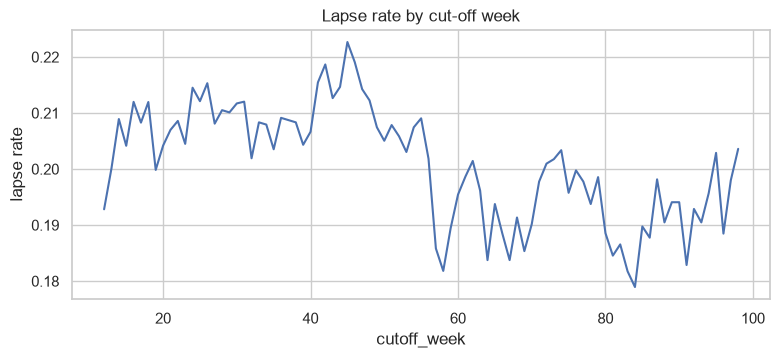

recency_bin
              mean    size
recency_bin               
0            0.058  114103
1            0.149   32730
2            0.239   15814
3-4          0.344   16221
5-8          0.490   14034
9+           0.715   21382

baskets_bin
              mean   size
baskets_bin              
0            0.756  15952
1-3          0.443  39592
4-8          0.195  49382
9-16         0.060  49007
17-32        0.016  40308
33+          0.009  20043

tenure_bin
             mean   size
tenure_bin              
1-12        0.206  22061
13-26       0.208  34972
27-52       0.207  64932
53+         0.193  92319



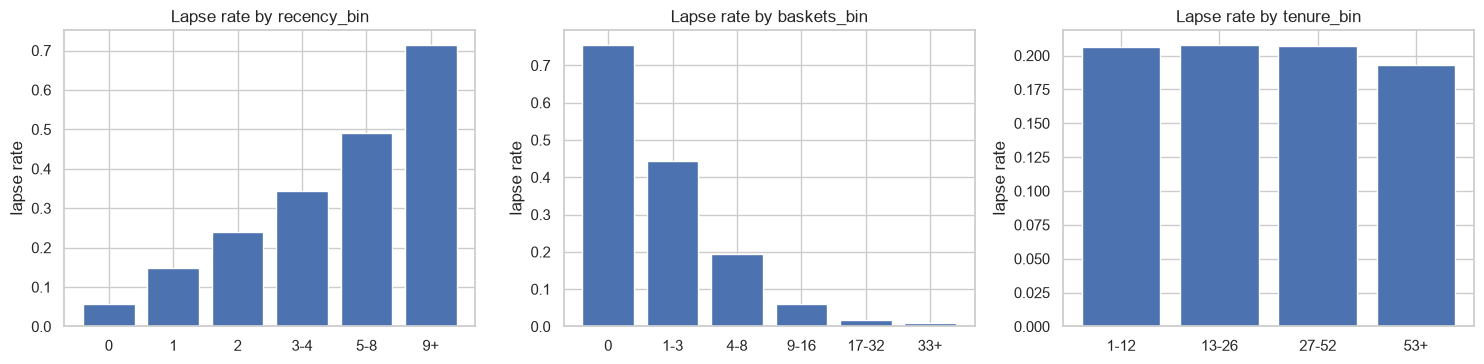

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# 1. class balance and drift over time
print(snap["lapse"].value_counts(normalize=True).round(3))
by_week = snap.groupby("cutoff_week")["lapse"].mean()
print(by_week.describe().round(3))
ax = by_week.plot(figsize=(9, 3.5), title="Lapse rate by cut-off week")
ax.set_ylabel("lapse rate"); plt.show()

# 2. lapse rate vs the main behaviour features
snap["recency_bin"] = pd.cut(snap["recency"], [-1, 0, 1, 2, 4, 8, 200],
                             labels=["0", "1", "2", "3-4", "5-8", "9+"])
snap["baskets_bin"] = pd.cut(snap["baskets_12w"], [-1, 0, 3, 8, 16, 32, 1000],
                             labels=["0", "1-3", "4-8", "9-16", "17-32", "33+"])
snap["tenure_bin"] = pd.cut(snap["tenure"], [0, 12, 26, 52, 98],
                            labels=["1-12", "13-26", "27-52", "53+"])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["recency_bin", "baskets_bin", "tenure_bin"]):
    t = snap.groupby(col, observed=True)["lapse"].agg(["mean", "size"])
    print(col); print(t.round(3)); print()
    ax.bar(t.index.astype(str), t["mean"])
    ax.set(title=f"Lapse rate by {col}", ylabel="lapse rate")
plt.tight_layout(); plt.show()

recency             4.67
tenure              0.02
spend_4w            2.41
spend_12w           2.47
baskets_4w          3.62
baskets_12w         3.70
active_weeks_12w    0.00
avg_basket_12w      2.20
dtype: float64


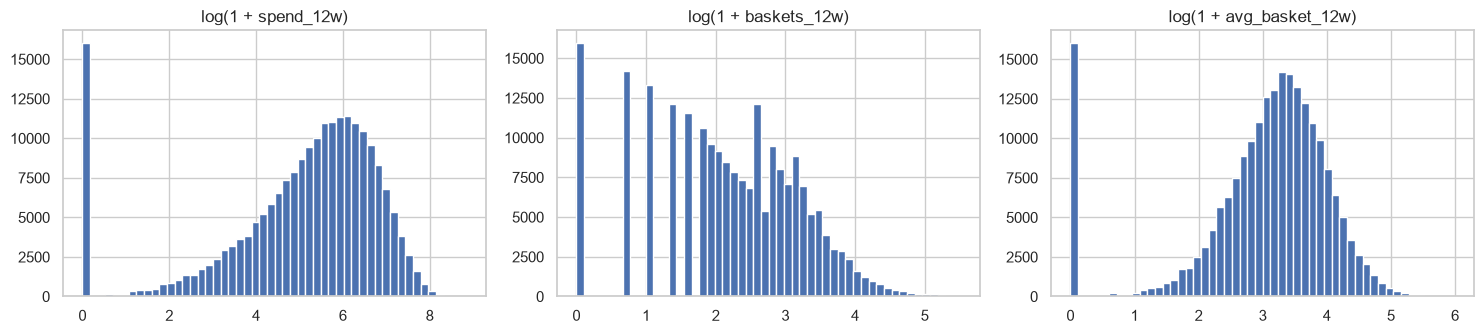

active_weeks_12w   -0.508
spend_12w          -0.323
spend_4w           -0.317
baskets_4w         -0.313
baskets_12w        -0.310
avg_basket_12w     -0.155
tenure             -0.018
recency             0.437
lapse               1.000
Name: lapse, dtype: float64


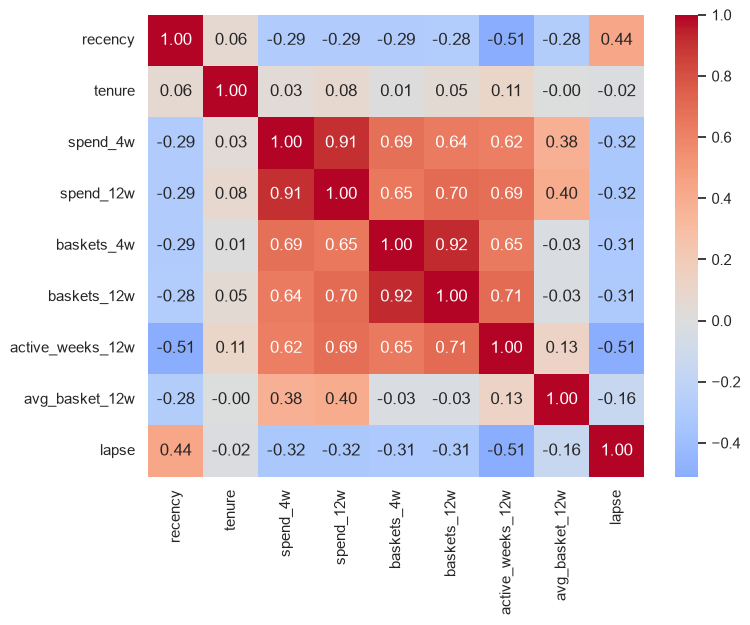

In [12]:
num = ["recency", "tenure", "spend_4w", "spend_12w", "baskets_4w",
       "baskets_12w", "active_weeks_12w", "avg_basket_12w"]

# 3. skew
print(snap[num].skew().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["spend_12w", "baskets_12w", "avg_basket_12w"]):
    ax.hist(np.log1p(snap[col]), bins=50)
    ax.set(title=f"log(1 + {col})")
plt.tight_layout(); plt.show()

# 4. correlations
corr = snap[num + ["lapse"]].corr()
print(corr["lapse"].sort_values().round(3))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

In [13]:
mask = np.triu(np.ones((len(num), len(num))), 1).astype(bool)
pairs = corr.loc[num, num].where(mask).stack()
print(pairs[pairs.abs() > 0.7].sort_values(ascending=False).round(2))

baskets_4w   baskets_12w         0.92
spend_4w     spend_12w           0.91
baskets_12w  active_weeks_12w    0.71
spend_12w    baskets_12w         0.70
dtype: float64


In [14]:
print(tx[["RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC"]].describe().round(3))
print("rows with a retail discount:", (tx["RETAIL_DISC"] != 0).mean().round(3))

       RETAIL_DISC  COUPON_DISC  COUPON_MATCH_DISC
count  2595732.000  2595732.000        2595732.000
mean        -0.539       -0.016             -0.003
std          1.249        0.217              0.040
min       -180.000      -55.930             -7.700
25%         -0.690        0.000              0.000
50%         -0.010        0.000              0.000
75%          0.000        0.000              0.000
max          3.990        0.000              0.000
rows with a retail discount: 0.502


In [15]:
snap = snap.drop(columns=["disc_share_12w", "redeem_12w", "redeem_ever"], errors="ignore")

tx["disc"] = -(tx["RETAIL_DISC"] + tx["COUPON_DISC"])
tx["gross"] = tx["SALES_VALUE"] + tx["disc"]
wd = (tx.groupby(["household_key", "WEEK_NO"])
        .agg(disc=("disc", "sum"), gross=("gross", "sum")).reset_index())

def mat(df, col):
    return (df.pivot(index="household_key", columns="WEEK_NO", values=col)
              .reindex(index=hh_ids, columns=weeks).fillna(0).to_numpy())

Dm, Gm = mat(wd, "disc"), mat(wd, "gross")

red = pd.read_csv(raw / "coupon_redempt.csv")
wk_end = wk["max"].to_numpy()                       # last DAY of each week 1..102
red["WEEK_NO"] = np.searchsorted(wk_end, red["DAY"]) + 1
rw = red.groupby(["household_key", "WEEK_NO"]).size().rename("n").reset_index()
Rm = mat(rw, "n")

rows = []
for t in range(12, 99):
    c = t - 1
    g12, d12 = Gm[:, c-11:c+1].sum(axis=1), Dm[:, c-11:c+1].sum(axis=1)
    rows.append(pd.DataFrame({
        "household_key": hh_ids, "cutoff_week": t,
        "disc_share_12w": np.where(g12 > 0, d12 / np.maximum(g12, 1e-9), 0.0),
        "redeem_12w": Rm[:, c-11:c+1].sum(axis=1),
        "redeem_ever": Rm[:, :c+1].sum(axis=1),
    }))
snap = snap.merge(pd.concat(rows), on=["household_key", "cutoff_week"], how="left")
print(snap.shape)

(214284, 17)


In [16]:
r = snap[snap["redeem_12w"] > 0].iloc[0]
hk, t = int(r["household_key"]), int(r["cutoff_week"])
lo, hi = wk.loc[t - 11, "min"], wk.loc[t, "max"]
manual = ((red["household_key"] == hk) & red["DAY"].between(lo, hi)).sum()
print("redeem_12w manual:", manual, "| table:", r["redeem_12w"])

print("share of snapshots with any redemption so far:", (snap["redeem_ever"] > 0).mean().round(3))
print(snap[["disc_share_12w", "redeem_12w", "redeem_ever"]].describe().round(3))
print(snap.groupby(snap["redeem_12w"] > 0)["lapse"].agg(["mean", "size"]).round(3))
print(snap.groupby(pd.qcut(snap["disc_share_12w"], 4, duplicates="drop"), observed=True)["lapse"].mean().round(3))

redeem_12w manual: 2 | table: 2.0
share of snapshots with any redemption so far: 0.063
       disc_share_12w  redeem_12w  redeem_ever
count      214284.000  214284.000   214284.000
mean            0.143       0.118        0.248
std             0.081       0.770        1.432
min             0.000       0.000        0.000
25%             0.096       0.000        0.000
50%             0.141       0.000        0.000
75%             0.188       0.000        0.000
max             0.778      23.000       35.000
             mean    size
redeem_12w               
False       0.209  205588
True        0.016    8696
disc_share_12w
(-0.001, 0.096]    0.396
(0.096, 0.141]     0.118
(0.141, 0.188]     0.119
(0.188, 0.778]     0.170
Name: lapse, dtype: float64


In [17]:
snap = snap.drop(columns=["camp_12w", "camp_ever"], errors="ignore")

camp = (pd.read_csv(raw / "campaign_table.csv")[["household_key", "CAMPAIGN"]]
          .merge(pd.read_csv(raw / "campaign_desc.csv")[["CAMPAIGN", "START_DAY"]], on="CAMPAIGN"))
camp["WEEK_NO"] = np.searchsorted(wk_end, camp["START_DAY"]) + 1
cw = camp.groupby(["household_key", "WEEK_NO"]).size().rename("n").reset_index()
Cm = mat(cw, "n")

rows = []
for t in range(12, 99):
    c = t - 1
    rows.append(pd.DataFrame({
        "household_key": hh_ids, "cutoff_week": t,
        "camp_12w": Cm[:, c-11:c+1].sum(axis=1),
        "camp_ever": Cm[:, :c+1].sum(axis=1),
    }))
snap = snap.merge(pd.concat(rows), on=["household_key", "cutoff_week"], how="left")
print(snap.shape, camp.shape)

(214284, 19) (7208, 4)


In [18]:
r = snap[snap["camp_12w"] > 0].iloc[0]
hk, t = int(r["household_key"]), int(r["cutoff_week"])
lo, hi = wk.loc[t - 11, "min"], wk.loc[t, "max"]
manual = ((camp["household_key"] == hk) & camp["START_DAY"].between(lo, hi)).sum()
print("camp_12w manual:", manual, "| table:", r["camp_12w"])

print("share of snapshots with a campaign started so far:", (snap["camp_ever"] > 0).mean().round(3))
print(snap.groupby(snap["camp_12w"] > 0)["lapse"].agg(["mean", "size"]).round(3))

camp_12w manual: 1 | table: 1.0
share of snapshots with a campaign started so far: 0.324
           mean    size
camp_12w               
False     0.251  159369
True      0.055   54915


In [19]:
snap = snap.drop(columns=["has_demo"], errors="ignore")
snap = snap[[c for c in snap.columns if not c.startswith("demo_")]]

demo = pd.read_csv(raw / "hh_demographic.csv")
print(demo.nunique())
for col in demo.columns.drop("household_key"):
    print(col, demo[col].value_counts().to_dict())

demo_cols = demo.columns.drop("household_key")
demo = demo.rename(columns={c: f"demo_{c}" for c in demo_cols})
demo["has_demo"] = 1
snap = snap.merge(demo, on="household_key", how="left")
snap["has_demo"] = snap["has_demo"].fillna(0).astype(int)
for c in [c for c in snap.columns if c.startswith("demo_")]:
    snap[c] = snap[c].astype(str).replace("nan", "missing")

print(snap.shape)
print(snap.groupby("has_demo")["lapse"].agg(["mean", "size"]).round(3))

classification_1       6
classification_2       3
classification_3      12
HOMEOWNER_DESC         5
classification_5       6
classification_4       5
KID_CATEGORY_DESC      4
household_key        801
dtype: int64
classification_1 {'Age Group4': 288, 'Age Group3': 194, 'Age Group2': 142, 'Age Group6': 72, 'Age Group5': 59, 'Age Group1': 46}
classification_2 {'Y': 344, 'X': 340, 'Z': 117}
classification_3 {'Level5': 192, 'Level4': 172, 'Level6': 96, 'Level3': 77, 'Level2': 74, 'Level1': 61, 'Level8': 38, 'Level7': 34, 'Level9': 30, 'Level12': 11, 'Level10': 11, 'Level11': 5}
HOMEOWNER_DESC {'Homeowner': 504, 'Unknown': 233, 'Renter': 42, 'Probable Renter': 11, 'Probable Owner': 11}
classification_5 {'Group5': 255, 'Group4': 187, 'Group3': 144, 'Group2': 95, 'Group6': 73, 'Group1': 47}
classification_4 {'2': 318, '1': 255, '3': 109, '5+': 66, '4': 53}
KID_CATEGORY_DESC {'None/Unknown': 558, '1': 114, '3+': 69, '2': 60}
(214284, 27)
           mean    size
has_demo               
0        

In [20]:
tx_by_hh = {k: g for k, g in tx.groupby("household_key")}
rng = np.random.default_rng(7)
bad = 0
for i in rng.choice(len(snap), 300, replace=False):
    r = snap.iloc[i]
    hk, t = int(r["household_key"]), int(r["cutoff_week"])
    lo, hi = wk.loc[t - 11, "min"], wk.loc[t, "max"]
    g = tx_by_hh[hk]
    w12 = g[g["WEEK_NO"].between(t - 11, t)]
    gross, disc = w12["gross"].sum(), w12["disc"].sum()
    rh, ch = red["household_key"] == hk, camp["household_key"] == hk
    checks = {
        "redeem_12w": (rh & red["DAY"].between(lo, hi)).sum() == r["redeem_12w"],
        "redeem_ever": (rh & (red["DAY"] <= hi)).sum() == r["redeem_ever"],
        "camp_12w": (ch & camp["START_DAY"].between(lo, hi)).sum() == r["camp_12w"],
        "camp_ever": (ch & (camp["START_DAY"] <= hi)).sum() == r["camp_ever"],
        "disc_share_12w": abs((disc / gross if gross > 0 else 0.0) - r["disc_share_12w"]) < 1e-6,
    }
    if not all(checks.values()):
        bad += 1
        print("MISMATCH", hk, t, [k for k, v in checks.items() if not v])
print("mismatches:", bad, "of 300")

mismatches: 0 of 300


In [21]:
snap = snap.drop(columns=["recency_bin", "baskets_bin", "tenure_bin"], errors="ignore")
Path("../data/processed").mkdir(exist_ok=True)
snap.to_csv("../data/processed/snapshots.csv", index=False)
print(snap.shape)

(214284, 24)


In [22]:
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score

path = Path("../data/processed/snapshots.csv")
cols = pd.read_csv(path, nrows=0).columns
snap = pd.read_csv(path, dtype={c: str for c in cols if c.startswith("demo_")})
print(snap.shape)

train = snap[snap["cutoff_week"] <= 66]
val   = snap[snap["cutoff_week"].between(71, 82)]
test  = snap[snap["cutoff_week"] >= 87]

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, d.shape, "lapse rate:", d["lapse"].mean().round(3))

(214284, 24)
train (134335, 24) lapse rate: 0.206
val (29976, 24) lapse rate: 0.196
test (29989, 24) lapse rate: 0.194


In [24]:
y = val["lapse"]
print("prevalence baseline PR-AUC:", round(y.mean(), 3))
print("recency as score  PR-AUC:", round(average_precision_score(y, val["recency"]), 3),
      "| ROC-AUC:", round(roc_auc_score(y, val["recency"]), 3))

for k in [3, 5, 9]:
    pred = (val["recency"] >= k).astype(int)
    print(f"rule recency >= {k}: precision",
          round(precision_score(y, pred), 3), "| recall", round(recall_score(y, pred), 3))

prevalence baseline PR-AUC: 0.196
recency as score  PR-AUC: 0.573 | ROC-AUC: 0.823
rule recency >= 3: precision 0.534 | recall 0.653
rule recency >= 5: precision 0.623 | recall 0.526
rule recency >= 9: precision 0.72 | recall 0.375


In [25]:
import time
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

A = ["recency", "tenure", "spend_4w", "spend_12w", "baskets_4w",
     "baskets_12w", "active_weeks_12w", "avg_basket_12w"]
B = A + ["disc_share_12w", "redeem_12w", "redeem_ever"]
demo_cols = [c for c in snap.columns if c.startswith("demo_")]
C = B + ["camp_12w", "camp_ever", "has_demo"] + demo_cols
sets = {"A": A, "B": B, "C": C}

def make_pre(feats, linear):
    cat = [c for c in feats if c in demo_cols]
    num = [c for c in feats if c not in cat]
    num_pipe = (make_pipeline(FunctionTransformer(np.log1p), StandardScaler())
                if linear else "passthrough")
    parts = [("num", num_pipe, num)]
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(parts)

models = {
    "LogReg": (LogisticRegression(max_iter=1000), True),
    "Tree":   (DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=42), False),
    "Forest": (RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50,
                                      n_jobs=-1, random_state=42), False),
    "XGB":    (XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1,
                             random_state=42), False),
}

rows = []
for set_name, feats in sets.items():
    for model_name, (est, linear) in models.items():
        t0 = time.time()
        pipe = Pipeline([("pre", make_pre(feats, linear)), ("model", est)])
        pipe.fit(train[feats], train["lapse"])
        p = pipe.predict_proba(val[feats])[:, 1]
        rows.append({"set": set_name, "model": model_name,
                     "PR_AUC": round(average_precision_score(val["lapse"], p), 3),
                     "ROC_AUC": round(roc_auc_score(val["lapse"], p), 3),
                     "seconds": round(time.time() - t0)})
        print(rows[-1])

results = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
print(results.to_string(index=False))
print("recency baseline PR-AUC: 0.573")

{'set': 'A', 'model': 'LogReg', 'PR_AUC': 0.638, 'ROC_AUC': 0.885, 'seconds': 0}
{'set': 'A', 'model': 'Tree', 'PR_AUC': 0.623, 'ROC_AUC': 0.882, 'seconds': 0}
{'set': 'A', 'model': 'Forest', 'PR_AUC': 0.639, 'ROC_AUC': 0.886, 'seconds': 11}
{'set': 'A', 'model': 'XGB', 'PR_AUC': 0.625, 'ROC_AUC': 0.88, 'seconds': 2}
{'set': 'B', 'model': 'LogReg', 'PR_AUC': 0.639, 'ROC_AUC': 0.885, 'seconds': 1}
{'set': 'B', 'model': 'Tree', 'PR_AUC': 0.622, 'ROC_AUC': 0.881, 'seconds': 1}
{'set': 'B', 'model': 'Forest', 'PR_AUC': 0.639, 'ROC_AUC': 0.887, 'seconds': 12}
{'set': 'B', 'model': 'XGB', 'PR_AUC': 0.618, 'ROC_AUC': 0.879, 'seconds': 2}
{'set': 'C', 'model': 'LogReg', 'PR_AUC': 0.646, 'ROC_AUC': 0.891, 'seconds': 3}
{'set': 'C', 'model': 'Tree', 'PR_AUC': 0.624, 'ROC_AUC': 0.885, 'seconds': 2}
{'set': 'C', 'model': 'Forest', 'PR_AUC': 0.645, 'ROC_AUC': 0.892, 'seconds': 17}
{'set': 'C', 'model': 'XGB', 'PR_AUC': 0.63, 'ROC_AUC': 0.886, 'seconds': 4}
set  model  PR_AUC  ROC_AUC  seconds
  C L

In [26]:
variants = {
    "B":                 B,
    "B + campaigns":     B + ["camp_12w", "camp_ever"],
    "B + has_demo only": B + ["has_demo"],
    "B + demo categories (incl. 'missing')": B + demo_cols,
    "C (everything)":    C,
}
rows = []
for vname, feats in variants.items():
    for mname in ["LogReg", "Forest"]:
        est, linear = models[mname]
        pipe = Pipeline([("pre", make_pre(feats, linear)), ("model", est)])
        pipe.fit(train[feats], train["lapse"])
        p = pipe.predict_proba(val[feats])[:, 1]
        rows.append({"variant": vname, "model": mname,
                     "PR_AUC": round(average_precision_score(val["lapse"], p), 3)})
print(pd.DataFrame(rows).pivot(index="variant", columns="model", values="PR_AUC"))

model                                  Forest  LogReg
variant                                              
B                                       0.639   0.639
B + campaigns                           0.640   0.641
B + demo categories (incl. 'missing')   0.646   0.645
B + has_demo only                       0.644   0.645
C (everything)                          0.645   0.646


In [35]:
from sklearn.base import clone
from sklearn.model_selection import ParameterSampler

FEATS = C

spaces = {
    "LogReg": (LogisticRegression(max_iter=2000), True,
               {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "Forest": (RandomForestClassifier(n_jobs=-1, random_state=42), False,
               {"n_estimators": [200, 300], "max_depth": [8, 12, 16, 20],
                "min_samples_leaf": [20, 50, 100, 200], "max_features": ["sqrt", 0.5]}),
    "XGB":    (XGBClassifier(subsample=0.8, eval_metric="logloss", n_jobs=-1, random_state=42), False,
               {"n_estimators": [100, 200, 400], "max_depth": [2, 3, 4, 6],
                "learning_rate": [0.02, 0.05, 0.1], "min_child_weight": [1, 10, 50],
                "colsample_bytree": [0.5, 0.8, 1.0]}),
}
n_iters = {"LogReg": 7, "Forest": 8, "XGB": 15}

best = {}
for mname, (est, linear, space) in spaces.items():
    results_m = []
    grid_size = int(np.prod([len(v) for v in space.values()]))
    for params in ParameterSampler(space, n_iter=min(n_iters[mname], grid_size), random_state=42):
        pipe = Pipeline([("pre", make_pre(FEATS, linear)),
                         ("model", clone(est).set_params(**params))])
        pipe.fit(train[FEATS], train["lapse"])
        p = pipe.predict_proba(val[FEATS])[:, 1]
        results_m.append((round(average_precision_score(val["lapse"], p), 4), params))
    results_m.sort(key=lambda x: -x[0])
    best[mname] = results_m[0]
    print(mname, "best PR-AUC:", results_m[0][0], results_m[0][1])
    print("   worst tried:", results_m[-1][0])

LogReg best PR-AUC: 0.6457 {'C': 0.3}
   worst tried: 0.6455
Forest best PR-AUC: 0.6471 {'n_estimators': 200, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 20}
   worst tried: 0.6417
XGB best PR-AUC: 0.6467 {'n_estimators': 200, 'min_child_weight': 50, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
   worst tried: 0.6372


In [36]:
from sklearn.metrics import brier_score_loss

print("Brier, constant prediction:",
      round(brier_score_loss(val["lapse"], np.full(len(val), train["lapse"].mean())), 4))

final = {}
for mname, (score, params) in best.items():
    est, linear, _ = spaces[mname]
    pipe = Pipeline([("pre", make_pre(FEATS, linear)),
                     ("model", clone(est).set_params(**params))])
    t0 = time.time()
    pipe.fit(train[FEATS], train["lapse"])
    p = pipe.predict_proba(val[FEATS])[:, 1]
    final[mname] = (pipe, p)
    print(mname,
          "| PR-AUC", round(average_precision_score(val["lapse"], p), 4),
          "| ROC-AUC", round(roc_auc_score(val["lapse"], p), 4),
          "| Brier", round(brier_score_loss(val["lapse"], p), 4),
          "| fit sec", round(time.time() - t0, 1))

Brier, constant prediction: 0.1575
LogReg | PR-AUC 0.6457 | ROC-AUC 0.891 | Brier 0.1014 | fit sec 2.7
Forest | PR-AUC 0.6471 | ROC-AUC 0.8919 | Brier 0.1008 | fit sec 18.4
XGB | PR-AUC 0.6467 | ROC-AUC 0.8921 | Brier 0.1008 | fit sec 2.7


In [29]:
print(len(FEATS), FEATS == B, FEATS == C)

21 False True


In [34]:
FEATS = B

In [31]:
print(len(FEATS), FEATS == B, FEATS == C)

11 True False


In [32]:
print(len(B), len(C))
print("FEATS has", len(FEATS), "features | is B:", FEATS == B, "| is C:", FEATS == C)

11 21
FEATS has 11 features | is B: True | is C: False


In [37]:
FEATS = B
print("Tuning on", len(FEATS), "features")          # must print 11

best = {}
for mname, (est, linear, space) in spaces.items():
    results_m = []
    grid_size = int(np.prod([len(v) for v in space.values()]))
    for params in ParameterSampler(space, n_iter=min(n_iters[mname], grid_size), random_state=42):
        pipe = Pipeline([("pre", make_pre(FEATS, linear)),
                         ("model", clone(est).set_params(**params))])
        pipe.fit(train[FEATS], train["lapse"])
        p = pipe.predict_proba(val[FEATS])[:, 1]
        results_m.append((round(average_precision_score(val["lapse"], p), 4), params))
    results_m.sort(key=lambda x: -x[0])
    best[mname] = results_m[0]
    print(mname, "best PR-AUC:", results_m[0][0], results_m[0][1], "| worst tried:", results_m[-1][0])

print("\nBrier, constant prediction:",
      round(brier_score_loss(val["lapse"], np.full(len(val), train["lapse"].mean())), 4))
final = {}
for mname, (score, params) in best.items():
    est, linear, _ = spaces[mname]
    pipe = Pipeline([("pre", make_pre(FEATS, linear)),
                     ("model", clone(est).set_params(**params))])
    t0 = time.time()
    pipe.fit(train[FEATS], train["lapse"])
    p = pipe.predict_proba(val[FEATS])[:, 1]
    final[mname] = (pipe, p)
    print(mname, "| PR-AUC", round(average_precision_score(val["lapse"], p), 4),
          "| ROC-AUC", round(roc_auc_score(val["lapse"], p), 4),
          "| Brier", round(brier_score_loss(val["lapse"], p), 4),
          "| fit sec", round(time.time() - t0, 1))

Tuning on 11 features
LogReg best PR-AUC: 0.6387 {'C': 1} | worst tried: 0.6385
Forest best PR-AUC: 0.6418 {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 8} | worst tried: 0.6373
XGB best PR-AUC: 0.6422 {'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.8} | worst tried: 0.6318

Brier, constant prediction: 0.1575
LogReg | PR-AUC 0.6387 | ROC-AUC 0.8848 | Brier 0.1031 | fit sec 0.7
Forest | PR-AUC 0.6418 | ROC-AUC 0.8871 | Brier 0.1022 | fit sec 11.7
XGB | PR-AUC 0.6422 | ROC-AUC 0.8871 | Brier 0.1031 | fit sec 1.4


In [39]:
from sklearn.metrics import precision_recall_curve

xgb_pipe, p = final["XGB"]
y = val["lapse"].to_numpy()

prec, rec, thr = precision_recall_curve(y, p)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
i = f1[:-1].argmax()
print("F1-best threshold:", round(thr[i], 3), "| precision", round(prec[i], 3),
      "| recall", round(rec[i], 3), "| F1", round(f1[i], 3))

print("\nthreshold table")
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = p >= t
    print(f"  p >= {t}: contacts {pred.mean():.1%} of households | "
          f"precision {y[pred].mean():.3f} | recall {y[pred].sum() / y.sum():.3f}")

print("\ncapacity view (contact the riskiest k%)")
order = np.argsort(-p)
for k in [0.05, 0.10, 0.20, 0.30]:
    n = int(len(p) * k)
    top = y[order[:n]]
    print(f"  top {int(k * 100)}%: precision {top.mean():.3f} | recall {top.sum() / y.sum():.3f} "
          f"| lift {top.mean() / y.mean():.2f}x")

print("\nrecency rules for comparison")
for k in [3, 5, 9]:
    pred = (val["recency"] >= k).to_numpy()
    print(f"  recency >= {k}: contacts {pred.mean():.1%} | precision {y[pred].mean():.3f} "
          f"| recall {y[pred].sum() / y.sum():.3f}")

F1-best threshold: 0.276 | precision 0.539 | recall 0.74 | F1 0.624

threshold table
  p >= 0.2: contacts 35.6% of households | precision 0.467 | recall 0.847
  p >= 0.3: contacts 24.4% of households | precision 0.560 | recall 0.697
  p >= 0.4: contacts 17.8% of households | precision 0.633 | recall 0.576
  p >= 0.5: contacts 11.1% of households | precision 0.711 | recall 0.404
  p >= 0.6: contacts 7.3% of households | precision 0.769 | recall 0.288

capacity view (contact the riskiest k%)
  top 5%: precision 0.786 | recall 0.201 | lift 4.02x
  top 10%: precision 0.728 | recall 0.372 | lift 3.72x
  top 20%: precision 0.605 | recall 0.618 | lift 3.09x
  top 30%: precision 0.510 | recall 0.782 | lift 2.61x

recency rules for comparison
  recency >= 3: contacts 23.9% | precision 0.534 | recall 0.653
  recency >= 5: contacts 16.5% | precision 0.623 | recall 0.526
  recency >= 9: contacts 10.2% | precision 0.720 | recall 0.375


baseline PR-AUC: 0.6422
         feature   drop    std
active_weeks_12w 0.0533 0.0018
         recency 0.0526 0.0029
      baskets_4w 0.0159 0.0021
     baskets_12w 0.0103 0.0010
          tenure 0.0033 0.0011
  avg_basket_12w 0.0016 0.0009
        spend_4w 0.0014 0.0005
       spend_12w 0.0014 0.0003
  disc_share_12w 0.0004 0.0001
      redeem_12w 0.0000 0.0000
     redeem_ever 0.0000 0.0000

group importance
  recency          drop 0.0540
  frequency        drop 0.2776
  spend            drop 0.0054
  tenure           drop 0.0023
  discount/coupon  drop 0.0004


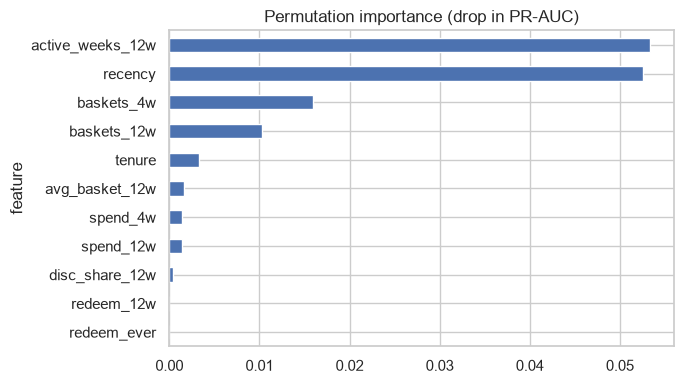

In [40]:
from sklearn.inspection import permutation_importance

xgb_pipe, _ = final["XGB"]
Xv, yv = val[FEATS], val["lapse"]
base = average_precision_score(yv, xgb_pipe.predict_proba(Xv)[:, 1])
print("baseline PR-AUC:", round(base, 4))

# 1. single-feature permutation importance
pi = permutation_importance(xgb_pipe, Xv, yv, scoring="average_precision",
                            n_repeats=5, random_state=42, n_jobs=1)
imp = (pd.DataFrame({"feature": FEATS, "drop": pi.importances_mean, "std": pi.importances_std})
         .sort_values("drop", ascending=False))
print(imp.round(4).to_string(index=False))

# 2. group permutation importance
groups = {
    "recency":          ["recency"],
    "frequency":        ["baskets_4w", "baskets_12w", "active_weeks_12w"],
    "spend":            ["spend_4w", "spend_12w", "avg_basket_12w"],
    "tenure":           ["tenure"],
    "discount/coupon":  ["disc_share_12w", "redeem_12w", "redeem_ever"],
}
rng = np.random.default_rng(42)
print("\ngroup importance")
for g, cols in groups.items():
    drops = []
    for _ in range(5):
        Xp = Xv.copy()
        Xp[cols] = Xp[cols].sample(frac=1, random_state=int(rng.integers(1e9))).to_numpy()
        drops.append(base - average_precision_score(yv, xgb_pipe.predict_proba(Xp)[:, 1]))
    print(f"  {g:16s} drop {np.mean(drops):.4f}")

# 3. plot
import matplotlib.pyplot as plt
imp.sort_values("drop").plot.barh(x="feature", y="drop", legend=False, figsize=(7, 4),
                                  title="Permutation importance (drop in PR-AUC)")
plt.tight_layout(); plt.show()

In [41]:
xgb_pipe, _ = final["XGB"]
Xt, yt = test[FEATS], test["lapse"].to_numpy()
pt = xgb_pipe.predict_proba(Xt)[:, 1]
THRESH = 0.30

print("test rows:", len(test), "| lapse rate:", round(yt.mean(), 3))
print("PR-AUC :", round(average_precision_score(yt, pt), 4),
      "| ROC-AUC:", round(roc_auc_score(yt, pt), 4))
print("Brier  :", round(brier_score_loss(yt, pt), 4),
      "| constant baseline:", round(brier_score_loss(yt, np.full(len(yt), train["lapse"].mean())), 4))
print("recency alone PR-AUC:", round(average_precision_score(yt, test["recency"]), 4))

pred = pt >= THRESH
print(f"\nthreshold {THRESH}: contacts {pred.mean():.1%} | precision {yt[pred].mean():.3f} "
      f"| recall {yt[pred].sum() / yt.sum():.3f}")

order = np.argsort(-pt)
for k in [0.05, 0.10, 0.20]:
    n = int(len(pt) * k)
    print(f"top {int(k*100)}%: precision {yt[order[:n]].mean():.3f} | lift {yt[order[:n]].mean() / yt.mean():.2f}x")

for k in [3, 5]:
    r = (test["recency"] >= k).to_numpy()
    print(f"recency >= {k}: contacts {r.mean():.1%} | precision {yt[r].mean():.3f} "
          f"| recall {yt[r].sum() / yt.sum():.3f}")

test rows: 29989 | lapse rate: 0.194
PR-AUC : 0.6223 | ROC-AUC: 0.8818
Brier  : 0.1048 | constant baseline: 0.1567
recency alone PR-AUC: 0.5541

threshold 0.3: contacts 23.8% | precision 0.561 | recall 0.687
top 5%: precision 0.770 | lift 3.96x
top 10%: precision 0.708 | lift 3.64x
top 20%: precision 0.597 | lift 3.07x
recency >= 3: contacts 23.6% | precision 0.523 | recall 0.635
recency >= 5: contacts 15.9% | precision 0.615 | recall 0.504
